# Food Delivery Time Prediction
### Machine Learning Laboratory &ndash; Mini Project

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv(r"C:\Users\L.THAMIZHARASI\Downloads\archive\train.csv")

df.columns = df.columns.str.strip()
print("Rows and columns:", df.shape)
print("\nFirst 5 rows:")
print(df.head())

Rows and columns: (45593, 20)

First 5 rows:
        ID Delivery_person_ID Delivery_person_Age Delivery_person_Ratings  \
0  0x4607     INDORES13DEL02                   37                     4.9   
1  0xb379     BANGRES18DEL02                   34                     4.5   
2  0x5d6d     BANGRES19DEL01                   23                     4.4   
3  0x7a6a    COIMBRES13DEL02                   38                     4.7   
4  0x70a2     CHENRES12DEL01                   32                     4.6   

   Restaurant_latitude  Restaurant_longitude  Delivery_location_latitude  \
0            22.745049             75.892471                   22.765049   
1            12.913041             77.683237                   13.043041   
2            12.914264             77.678400                   12.924264   
3            11.003669             76.976494                   11.053669   
4            12.972793             80.249982                   13.012793   

   Delivery_location_longitude  Ord

In [2]:
needed = [
    "Delivery_person_Age", "Delivery_person_Ratings", "Restaurant_latitude",
    "Restaurant_longitude", "Delivery_location_latitude", "Delivery_location_longitude",
    "Order_Date", "Time_Orderd", "Time_Order_picked", "Weatherconditions",
    "Road_traffic_density", "Vehicle_condition", "Type_of_order", "Type_of_vehicle",
    "multiple_deliveries", "Festival", "City", "Time_taken(min)"
]

missing = [c for c in needed if c not in df.columns]
if missing:
    print("Missing columns:", missing)
    print("Available columns:", list(df.columns))
    raise ValueError("Required columns are missing!")

df = df.drop(columns=["ID", "Delivery_person_ID"], errors="ignore")

df["Time_taken(min)"] = (
    df["Time_taken(min)"].astype(str).str.split().str[-1].astype(int)
)

df["Weatherconditions"] = (
    df["Weatherconditions"].astype(str).str.replace("conditions ", "", regex=False)
)

text_cols = ["Weatherconditions", "Road_traffic_density", "Type_of_order",
             "Type_of_vehicle", "Festival", "City", "Time_Orderd"]
num_cols = ["Delivery_person_Age", "Delivery_person_Ratings", "multiple_deliveries"]

for col in text_cols:
    df[col] = df[col].astype(str).str.strip()
    df[col] = df[col].replace("NaN", np.nan)
    df[col] = df[col].replace("nan", np.nan)

for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

for col in text_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

print("\nMissing values after cleaning:")
print(df.isnull().sum())


Missing values after cleaning:
Delivery_person_Age            0
Delivery_person_Ratings        0
Restaurant_latitude            0
Restaurant_longitude           0
Delivery_location_latitude     0
Delivery_location_longitude    0
Order_Date                     0
Time_Orderd                    0
Time_Order_picked              0
Weatherconditions              0
Road_traffic_density           0
Vehicle_condition              0
Type_of_order                  0
Type_of_vehicle                0
multiple_deliveries            0
Festival                       0
City                           0
Time_taken(min)                0
dtype: int64


In [3]:
coordinate_cols = [
    "Restaurant_latitude", "Restaurant_longitude",
    "Delivery_location_latitude", "Delivery_location_longitude"
]
for col in coordinate_cols:
    df[col] = df[col].abs()

df = df[(df["Restaurant_latitude"] > 0) & (df["Restaurant_longitude"] > 0)]

lat = df["Delivery_location_latitude"] - df["Restaurant_latitude"]
lon = df["Delivery_location_longitude"] - df["Restaurant_longitude"]
df["distance_km"] = np.sqrt(lat**2 + lon**2) * 111

df["hour"] = pd.to_datetime(df["Time_Orderd"], format="%H:%M:%S",
                             errors="coerce").dt.hour
df["hour"] = df["hour"].fillna(df["hour"].median())

print("\nDataset after feature engineering:")
print(df.shape)


Dataset after feature engineering:
(41953, 20)


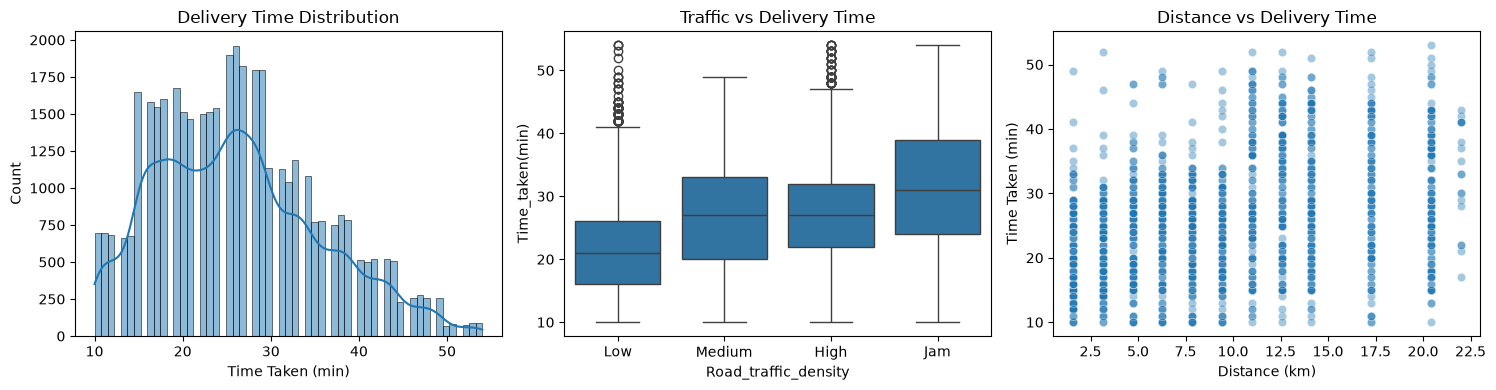

In [4]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.histplot(df["Time_taken(min)"], kde=True)
plt.title("Delivery Time Distribution")
plt.xlabel("Time Taken (min)")

plt.subplot(1, 3, 2)
sns.boxplot(x="Road_traffic_density", y="Time_taken(min)", data=df,
            order=["Low", "Medium", "High", "Jam"])
plt.title("Traffic vs Delivery Time")

plt.subplot(1, 3, 3)
sample_size = min(1500, len(df))
sns.scatterplot(x="distance_km", y="Time_taken(min)",
                 data=df.sample(sample_size, random_state=42), alpha=0.4)
plt.title("Distance vs Delivery Time")
plt.xlabel("Distance (km)")
plt.ylabel("Time Taken (min)")

plt.tight_layout()
plt.show()

In [5]:
y = df["Time_taken(min)"]
X = df.drop(columns=["Time_taken(min)", "Order_Date", "Time_Orderd",
                      "Time_Order_picked", "Restaurant_latitude",
                      "Restaurant_longitude", "Delivery_location_latitude",
                      "Delivery_location_longitude"], errors="ignore")

X = pd.get_dummies(X, drop_first=True)
X = X.astype(float)

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("\nTraining data:", x_train.shape)
print("Testing data :", x_test.shape)


Training data: (33562, 23)
Testing data : (8391, 23)


In [6]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

best_name, best_mae, best_pred = "", float("inf"), None
results = []

print("\n================ MODEL RESULTS ================")
for name, model in models.items():
    print("\nTraining:", name)
    model.fit(x_train, y_train)
    pred = model.predict(x_test)

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    results.append([name, mae, rmse, r2])
    print("MAE  :", round(mae, 2))
    print("RMSE :", round(rmse, 2))
    print("R2   :", round(r2, 3))

    if mae < best_mae:
        best_mae, best_name, best_pred = mae, name, pred

results_df = pd.DataFrame(results, columns=["Model", "MAE", "RMSE", "R2 Score"])

print("\n================ MODEL COMPARISON ================")
print(results_df)

print("\n===================================================")
print("BEST MODEL:", best_name)
print("BEST MAE:", round(best_mae, 2))
print("===================================================")


================ MODEL RESULTS ================

Training: Linear Regression
MAE  : 4.77
RMSE : 6.03
R2   : 0.578

Training: Random Forest
MAE  : 3.23
RMSE : 4.13
R2   : 0.802

Training: Gradient Boosting
MAE  : 3.65
RMSE : 4.59
R2   : 0.756

================ MODEL COMPARISON ================
               Model       MAE      RMSE  R2 Score
0  Linear Regression  4.765546  6.027525  0.578311
1      Random Forest  3.228734  4.130079  0.802016
2  Gradient Boosting  3.645372  4.587453  0.755737

BEST MODEL: Random Forest
BEST MAE: 3.23


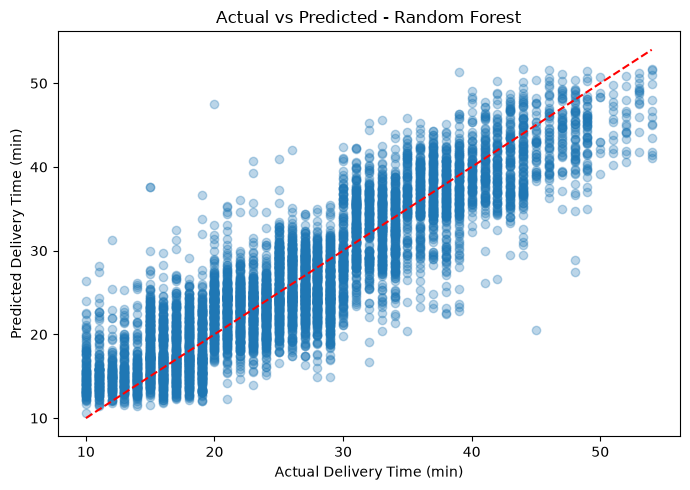

In [7]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, best_pred, alpha=0.3)
min_v, max_v = min(y_test.min(), best_pred.min()), max(y_test.max(), best_pred.max())
plt.plot([min_v, max_v], [min_v, max_v], "r--")
plt.xlabel("Actual Delivery Time (min)")
plt.ylabel("Predicted Delivery Time (min)")
plt.title("Actual vs Predicted - " + best_name)
plt.tight_layout()
plt.show()

In [8]:
print("\nSample Predictions:")
prediction_df = pd.DataFrame({
    "Actual Time": y_test.values[:10],
    "Predicted Time": np.round(best_pred[:10], 2)
})
print(prediction_df)


Sample Predictions:
   Actual Time  Predicted Time
0           21           27.51
1           18           16.08
2           25           27.52
3           24           22.66
4           40           34.00
5           20           24.09
6           22           20.79
7           15           24.04
8           31           35.62
9           20           19.67
